# Parity is a zigzag: how many units does a shallow network really need?

Measures the four predictions Z1 to Z4 of the section "The measurement: how many units does a shallow
network really need?" in [`docs/connections/p-versus-np.md`](../../docs/connections/p-versus-np.md). The
predictions, the stop rule (200 starts for each number of units `k` from 1 to 8, 3,000 steps of gradient
descent for each start, one fixed seed, the hinge loss with margin 0.05) are in the note, which was pushed
before this notebook was run. None of them is changed here.

**Set by the helper before the run, not in the pushed note** (chosen once, from first principles, and not
tried against alternatives):

- **Optimiser:** Adam (first-moment decay 0.9, second-moment decay 0.999, `eps` 1e-8) with **step size 0.01**
  for every parameter. Reason: the counts run from 0 to 8 and the outputs are of order 1, so a step of 0.01
  moves a kink by about 0.01 per step; 3,000 steps allow a kink to travel up to 30, more than the whole
  range, while one step stays small beside the gap of 1 between neighbouring counts.
- **Trained parameters:** all three of each unit: gain, slope and bias.
- **Starting points:** slope +1 or -1 with equal chance, kink `-bias / slope` uniform on [-1, 9], gain normal
  with mean 0 and standard deviation 1.
- **Seed:** `numpy.random.default_rng(0)`, one generator for the whole search, drawn for `k` = 1, 2, ..., 8 in
  that order, in the order slopes, kinks, gains for each `k`.
- **What is recorded:** the margin of each start at the last step (step 3,000), not the best margin along the
  way. A start "succeeds" if that margin is strictly above 0.

**The model.** The Lean one: `output(count) = sum over units j of gain[j] * max(slope[j] * count + bias[j], 0)`,
with no constant added at the output. For `n` = 8 bits the input is the count of bits that are on, 0 to 8.
The network "computes parity" if its output is below 1/2 at every even count and above 1/2 at every odd count.
The **margin** is the smallest over the nine counts of `sign * (output - 1/2)`, with sign +1 at odd counts and
-1 at even counts; the network computes parity exactly when the margin is above 0. There is no Euclidean
distance in this notebook: the margin is a vertical quantity, and so is the loss.

**Measured, found by search, from the formula.** "Found by search" is used only for the gradient-descent
search. "From the formula" is used for numbers that come from evaluating a formula (the tent layers, the
neuron counts). A prediction that fails prints a line starting with `[FAIL]` and the notebook still runs to
the end. Checks that the measurement itself is valid (the gradient against finite differences, a separate
recomputation of the margin) are asserted and stop the notebook. Checks that hold by construction are printed
as `[by construction, cannot fail]` and are not counted. A last section, "Diagnostic", was **added after the run and after a
second reader's review**; it is not one of the predictions and changes no verdict.

In [1]:
import math
import sys
import time
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import linprog

ROOT = next(folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / "CLAUDE.md").exists())
sys.path.insert(0, str(ROOT / "experiments" / "part1"))
from common import use_style, NEAREST, VERTICAL, BOUND, MODEL, BEFORE  # sets torch's default dtype; unused here

use_style()

BIT_COUNT = 8                            # n: the number of bits
COUNTS = np.arange(BIT_COUNT + 1, dtype=float)          # the nine counts 0, 1, ..., 8
SIGNS = np.where(COUNTS % 2 == 1, 1.0, -1.0)            # +1 at odd counts, -1 at even counts
UNIT_COUNTS = tuple(range(1, BIT_COUNT + 1))            # k = 1, ..., 8
START_COUNT = 200                        # random starting points for each k (note)
STEP_COUNT = 3000                        # steps of gradient descent for each start (note)
HINGE_MARGIN = 0.05                      # the loss is zero when every count is 0.05 on the right side (note)
SEED = 0                                 # numpy default_rng(SEED), helper's choice
LEARNING_RATE = 0.01                     # Adam step size, helper's choice
FIRST_DECAY, SECOND_DECAY, EPSILON = 0.9, 0.999, 1e-8
KINK_LOW, KINK_HIGH = -1.0, 9.0          # starting kinks are uniform on this range, helper's choice
GAIN_SPREAD = 1.0                        # starting gains are normal with this standard deviation, helper's choice
FIGURE_PATH = ROOT / "graphs" / "parity_zigzag.png"

VERDICTS = {}


def check(condition, text):
    # A validity check that can fail. It stops the notebook when it fails.
    print(("[PASS] check: " if condition else "[FAIL] check: ") + text)
    assert condition, text


def note_by_construction(text):
    # A line that holds because of how the code is written. It is not evidence and is not counted.
    print("[by construction, cannot fail] " + text)


def give_verdict(name, passed, text):
    # A prediction. It never stops the notebook: a failure is printed and kept for the summary.
    VERDICTS[name] = passed
    print(("[PASS] " if passed else "[FAIL] ") + text)


def evaluate_network_by_loop(gains, slopes, biases, count):
    # The formula, one unit at a time, with plain floats. Used only to check the vectorised code.
    total = 0.0
    for gain, slope, bias in zip(gains, slopes, biases):
        total += float(gain) * max(float(slope) * count + float(bias), 0.0)
    return total


def compute_margin_by_loop(gains, slopes, biases):
    # The margin recomputed in a separate function from the formula, never touching the training code.
    worst = math.inf
    for count in range(BIT_COUNT + 1):
        output = evaluate_network_by_loop(gains, slopes, biases, count)
        sign = 1.0 if count % 2 == 1 else -1.0
        worst = min(worst, sign * (output - 0.5))
    return worst


def compute_outputs(gains, slopes, biases):
    # Outputs of many networks at once. Arrays have shape (networks, units); the result (networks, counts).
    pre_activation = slopes[:, :, None] * COUNTS[None, None, :] + biases[:, :, None]
    return np.sum(gains[:, :, None] * np.maximum(pre_activation, 0.0), axis=1)


def compute_margins(gains, slopes, biases):
    outputs = compute_outputs(gains, slopes, biases)
    return np.min(SIGNS[None, :] * (outputs - 0.5), axis=1)


def compute_loss(gains, slopes, biases):
    outputs = compute_outputs(gains, slopes, biases)
    return np.sum(np.maximum(0.0, HINGE_MARGIN - SIGNS[None, :] * (outputs - 0.5)), axis=1)


def compute_gradient(gains, slopes, biases):
    # Gradient of the hinge loss of each network with respect to its own gains, slopes and biases.
    pre_activation = slopes[:, :, None] * COUNTS[None, None, :] + biases[:, :, None]
    is_on = pre_activation > 0.0
    relu = np.where(is_on, pre_activation, 0.0)
    outputs = np.sum(gains[:, :, None] * relu, axis=1)
    hinge_on = (HINGE_MARGIN - SIGNS[None, :] * (outputs - 0.5)) > 0.0
    output_slope = -SIGNS[None, :] * hinge_on                  # d loss / d output at each count
    gain_gradient = np.einsum("sc,skc->sk", output_slope, relu)
    slope_gradient = gains * np.einsum("sc,skc->sk", output_slope, is_on * COUNTS[None, None, :])
    bias_gradient = gains * np.einsum("sc,skc->sk", output_slope, is_on.astype(float))
    return gain_gradient, slope_gradient, bias_gradient


def train_networks(gains, slopes, biases):
    # Adam on the hinge loss, STEP_COUNT steps, all networks at once. Returns the final parameters.
    parameters = [gains.copy(), slopes.copy(), biases.copy()]
    first_moment = [np.zeros_like(item) for item in parameters]
    second_moment = [np.zeros_like(item) for item in parameters]
    for step in range(1, STEP_COUNT + 1):
        gradients = compute_gradient(*parameters)
        for index in range(3):
            first_moment[index] = FIRST_DECAY * first_moment[index] + (1 - FIRST_DECAY) * gradients[index]
            second_moment[index] = SECOND_DECAY * second_moment[index] + (1 - SECOND_DECAY) * gradients[index] ** 2
            corrected_first = first_moment[index] / (1 - FIRST_DECAY ** step)
            corrected_second = second_moment[index] / (1 - SECOND_DECAY ** step)
            parameters[index] -= LEARNING_RATE * corrected_first / (np.sqrt(corrected_second) + EPSILON)
    return parameters

## Validity checks on the search code (asserted; they can fail)

(1) The vectorised output and the margin agree with the separate loop version on 1,000 random networks.
(2) The hand-written gradient agrees with finite differences of the loss (central, step 1e-6) on random
networks whose pre-activations are not within 1e-3 of a kink, where the loss is smooth.

In [2]:
check_rng = np.random.default_rng(12345)       # separate generator: the search below uses default_rng(SEED) only
test_gains = check_rng.normal(0.0, 1.0, (1000, 5))
test_slopes = check_rng.choice([-1.0, 1.0], (1000, 5)) * check_rng.uniform(0.3, 2.0, (1000, 5))
test_biases = check_rng.uniform(-8.0, 8.0, (1000, 5))
vector_margins = compute_margins(test_gains, test_slopes, test_biases)
loop_margins = np.array([compute_margin_by_loop(*row) for row in zip(test_gains, test_slopes, test_biases)])
check(float(np.abs(vector_margins - loop_margins).max()) < 1e-12,
      f"vectorised margin equals the loop margin on 1000 random networks (largest difference "
      f"{float(np.abs(vector_margins - loop_margins).max()):.1e})")

pre_activation = test_slopes[:, :, None] * COUNTS[None, None, :] + test_biases[:, :, None]
smooth = np.abs(pre_activation).min(axis=(1, 2)) > 1e-3            # no unit sits within 1e-3 of a kink
smooth_indices = np.flatnonzero(smooth)[:200]
parameters = [test_gains[smooth_indices], test_slopes[smooth_indices], test_biases[smooth_indices]]
analytic = compute_gradient(*parameters)
FINITE_STEP = 1e-6
worst_gradient_difference = 0.0
for index in range(3):
    numeric = np.zeros_like(parameters[index])
    for unit in range(parameters[index].shape[1]):
        plus = [item.copy() for item in parameters]
        minus = [item.copy() for item in parameters]
        plus[index][:, unit] += FINITE_STEP
        minus[index][:, unit] -= FINITE_STEP
        numeric[:, unit] = (compute_loss(*plus) - compute_loss(*minus)) / (2 * FINITE_STEP)
    worst_gradient_difference = max(worst_gradient_difference, float(np.abs(numeric - analytic[index]).max()))
check(worst_gradient_difference < 1e-4,
      f"hand-written gradient equals finite differences on {smooth_indices.size} smooth networks "
      f"(largest difference {worst_gradient_difference:.1e})")

[PASS] check: vectorised margin equals the loop margin on 1000 random networks (largest difference 0.0e+00)
[PASS] check: hand-written gradient equals finite differences on 200 smooth networks (largest difference 3.4e-08)


## The search

For each `k` from 1 to 8: 200 starting points drawn as described in the first cell, 3,000 steps of Adam on
the hinge loss, the margin recorded at the last step. The recorded margin of the best start is recomputed in
the separate loop function from the stored final parameters, and every successful start is recomputed too;
the recomputed numbers must equal the recorded ones (asserted).

In [3]:
search_rng = np.random.default_rng(SEED)
search_results = {}
search_start_time = time.perf_counter()
for unit_count in UNIT_COUNTS:
    start_slopes = search_rng.choice([-1.0, 1.0], (START_COUNT, unit_count))
    start_kinks = search_rng.uniform(KINK_LOW, KINK_HIGH, (START_COUNT, unit_count))
    start_biases = -start_kinks * start_slopes
    start_gains = search_rng.normal(0.0, GAIN_SPREAD, (START_COUNT, unit_count))
    final_gains, final_slopes, final_biases = train_networks(start_gains, start_slopes, start_biases)
    margins = compute_margins(final_gains, final_slopes, final_biases)
    search_results[unit_count] = {"gains": final_gains, "slopes": final_slopes, "biases": final_biases,
                                  "margins": margins, "losses": compute_loss(final_gains, final_slopes, final_biases)}
search_seconds = time.perf_counter() - search_start_time
print(f"search: {len(UNIT_COUNTS)} values of k, {START_COUNT} starts each, {STEP_COUNT} steps each")
print(f"timing, differs between runs: the search took {search_seconds:.1f} seconds")

print(f"{'k':>2} {'best margin (found by search)':>30} {'starts with margin > 0':>24} {'starts with loss 0':>20}")
for unit_count in UNIT_COUNTS:
    result = search_results[unit_count]
    best = int(np.argmax(result["margins"]))
    result["best_index"] = best
    result["success_count"] = int(np.sum(result["margins"] > 0.0))
    result["zero_loss_count"] = int(np.sum(result["losses"] <= 1e-12))
    recomputed = compute_margin_by_loop(result["gains"][best], result["slopes"][best], result["biases"][best])
    check(abs(recomputed - result["margins"][best]) < 1e-9,
          f"k = {unit_count}: margin of the best start recomputed in a separate function equals the recorded one "
          f"({recomputed:.6f} against {result['margins'][best]:.6f})")
    for index in np.flatnonzero(result["margins"] > 0.0):
        again = compute_margin_by_loop(result["gains"][index], result["slopes"][index], result["biases"][index])
        check(abs(again - result["margins"][index]) < 1e-9 and again > 0.0,
              f"k = {unit_count}: successful start {int(index)} recomputed separately has margin {again:.6f} > 0")
    print(f"{unit_count:>2} {float(result['margins'][best]):>30.6f} {result['success_count']:>24d} {result['zero_loss_count']:>20d}")

search: 8 values of k, 200 starts each, 3000 steps each
timing, differs between runs: the search took 3.4 seconds
 k  best margin (found by search)   starts with margin > 0   starts with loss 0
[PASS] check: k = 1: margin of the best start recomputed in a separate function equals the recorded one (-0.010121 against -0.010121)
 1                      -0.010121                        0                    0
[PASS] check: k = 2: margin of the best start recomputed in a separate function equals the recorded one (-0.026449 against -0.026449)
 2                      -0.026449                        0                    0
[PASS] check: k = 3: margin of the best start recomputed in a separate function equals the recorded one (-0.012795 against -0.012795)
 3                      -0.012795                        0                    0
[PASS] check: k = 4: margin of the best start recomputed in a separate function equals the recorded one (-0.019669 against -0.019669)
 4                      -0.019

## Z1 and Z2

**Z1 (the theorem; prediction fixed in the note):** for `k` = 1, 2, 3 no start reaches a margin above 0. This
is statement 3 of the note, proved in Lean (it needs at least `8 / 2` = 4 units), so a failure would mean a
mistake in this notebook, and the notebook stops.

**Z2 (the claim `n - 1` = 7; fixed in the note):** for `k` = 4, 5, 6 no start reaches a margin above 0. It
counts against the claim if any single start, for any of these `k`, does. If one does, its weights are
printed, its margin is recomputed in the separate function, `[FAIL] Z2` is printed, and the notebook carries
on. A search that finds nothing does not prove that nothing exists.

In [4]:
def describe_network(unit_count, index):
    result = search_results[unit_count]
    rows = []
    for gain, slope, bias in zip(result["gains"][index], result["slopes"][index], result["biases"][index]):
        kink = -bias / slope if slope != 0.0 else float("nan")
        rows.append(f"gain {gain:+.4f}, slope {slope:+.4f}, bias {bias:+.4f} (kink at {kink:+.4f})")
    return rows


z1_successes = {unit_count: search_results[unit_count]["success_count"] for unit_count in (1, 2, 3)}
z1_passed = all(value == 0 for value in z1_successes.values())
give_verdict("Z1", z1_passed,
             "Z1: successful starts for k = 1, 2, 3: " + ", ".join(f"k = {key}: {value}" for key, value in z1_successes.items())
             + "; best margins " + ", ".join(f"{float(search_results[key]['margins'].max()):.4f}" for key in (1, 2, 3))
             + "; predicted none")
assert z1_passed, "Z1 is a Lean theorem: a success for k = 1, 2, 3 means a bug in the notebook"

z2_successes = {unit_count: search_results[unit_count]["success_count"] for unit_count in (4, 5, 6)}
z2_passed = all(value == 0 for value in z2_successes.values())
z3_search_found = all(search_results[unit_count]["success_count"] > 0 for unit_count in (7, 8))     # the same counts Z3 uses, below
z2_suffix = "" if z3_search_found else (" (weak: Z3 failed, so the search could not have found a network even if one existed)")
print("Z2: successful starts for k = 4, 5, 6: " + ", ".join(f"k = {key}: {value}" for key, value in z2_successes.items())
      + "; best margins " + ", ".join(f"{float(search_results[key]['margins'].max()):.4f}" for key in (4, 5, 6)) + z2_suffix)
if not z2_passed:
    for unit_count in (4, 5, 6):
        result = search_results[unit_count]
        if result["success_count"] > 0:
            best = result["best_index"]
            print(f"  weights of the best successful start for k = {unit_count} (start {best}):")
            for row in describe_network(unit_count, best):
                print("    " + row)
            outputs = [evaluate_network_by_loop(result["gains"][best], result["slopes"][best], result["biases"][best], count)
                       for count in range(BIT_COUNT + 1)]
            print("    output at counts 0 to 8, evaluated again in the separate function: "
                  + ", ".join(f"{value:.4f}" for value in outputs))
            print(f"    margin recomputed separately: "
                  f"{compute_margin_by_loop(result['gains'][best], result['slopes'][best], result['biases'][best]):.6f}")
give_verdict("Z2", z2_passed,
             "Z2: starts with a margin above 0 for k = 4, 5, 6, found by search: "
             + ", ".join(f"k = {key}: {value}" for key, value in z2_successes.items()) + "; predicted none" + z2_suffix)

[PASS] Z1: successful starts for k = 1, 2, 3: k = 1: 0, k = 2: 0, k = 3: 0; best margins -0.0101, -0.0264, -0.0128; predicted none
Z2: successful starts for k = 4, 5, 6: k = 4: 0, k = 5: 0, k = 6: 0; best margins -0.0197, -0.0041, -0.0188 (weak: Z3 failed, so the search could not have found a network even if one existed)
[PASS] Z2: starts with a margin above 0 for k = 4, 5, 6, found by search: k = 4: 0, k = 5: 0, k = 6: 0; predicted none (weak: Z3 failed, so the search could not have found a network even if one existed)


## Z3: enough units

**Construction (by construction, not evidence).** A 7-unit network with kinks at the counts 1 to 7. Each unit
is `max(+(count - kink), 0)` or `max(-(count - kink), 0)`. For each of the 2^7 choices of orientation a small
linear programme finds the gains that maximise the margin (gains limited to between -50 and 50, margin capped at
1). The best orientation is kept, its margin is recomputed in the separate function, and it is asserted
positive. The note says such a network exists, so this holds by construction and is not counted.

**Prediction Z3 (fixed in the note):** the search finds a margin above 0 for `k` = 7, and for `k` = 8, from at
least one of the 200 starts each. It counts against the prediction, and the search is then too weak for Z2 to
be good evidence, if either has no success. Nothing is tuned to rescue it.

In [5]:
KINK_POSITIONS = np.arange(1, 8, dtype=float)             # the counts 1 to 7
best_margin_by_construction, best_orientation, best_gains = -math.inf, None, None
for orientation in product([1.0, -1.0], repeat=len(KINK_POSITIONS)):
    orientation_array = np.array(orientation)
    basis = np.maximum(orientation_array[None, :] * (COUNTS[:, None] - KINK_POSITIONS[None, :]), 0.0)   # (counts, units)
    # variables: seven gains, then the margin. Maximise the margin subject to  sign * (basis @ gains - 1/2) >= margin.
    objective = np.zeros(len(KINK_POSITIONS) + 1)
    objective[-1] = -1.0
    constraint_matrix = np.hstack([-SIGNS[:, None] * basis, np.ones((COUNTS.size, 1))])
    constraint_bound = -0.5 * SIGNS
    solution = linprog(objective, A_ub=constraint_matrix, b_ub=constraint_bound,
                       bounds=[(-50.0, 50.0)] * len(KINK_POSITIONS) + [(-1.0, 1.0)], method="highs")
    if solution.status == 0 and solution.x[-1] > best_margin_by_construction:
        best_margin_by_construction = float(solution.x[-1])
        best_orientation, best_gains = orientation_array, solution.x[:-1].copy()

construction_slopes = best_orientation
construction_biases = -best_orientation * KINK_POSITIONS
verified_margin = compute_margin_by_loop(best_gains, construction_slopes, construction_biases)
assert verified_margin > 0.0, "the 7-unit construction must compute parity"
construction_outputs = [evaluate_network_by_loop(best_gains, construction_slopes, construction_biases, count)
                        for count in range(BIT_COUNT + 1)]
note_by_construction(f"a 7-unit network with kinks at the counts 1 to 7 computes parity: margin {verified_margin:.4f} "
                     f"(the linear programme reported {best_margin_by_construction:.4f}); not evidence")
print("  orientations (+1: rises after the kink, -1: falls after it): " + ", ".join(f"{int(value):+d}" for value in best_orientation))
print("  gains: " + ", ".join(f"{value:+.4f}" for value in best_gains))
print("  output at counts 0 to 8 (from the formula): " + ", ".join(f"{value:.4f}" for value in construction_outputs))
assert abs(verified_margin - best_margin_by_construction) < 1e-6

z3_by_unit = {unit_count: search_results[unit_count]["success_count"] for unit_count in (7, 8)}
z3_passed = all(value > 0 for value in z3_by_unit.values())
print("Z3: starts with a margin above 0, found by search: " + ", ".join(f"k = {key}: {value}" for key, value in z3_by_unit.items())
      + "; best margins " + ", ".join(f"{float(search_results[key]['margins'].max()):.4f}" for key in (7, 8)))
give_verdict("Z3", z3_passed,
             "Z3: search finds a margin above 0 for k = 7 (" + str(z3_by_unit[7]) + " starts) and for k = 8 ("
             + str(z3_by_unit[8]) + " starts); predicted at least one each")
if not z3_passed:
    print("the search could not find a network that is known to exist, for k = "
          + ", ".join(str(key) for key, value in z3_by_unit.items() if value == 0)
          + ", so the search is weak and the result of Z2 is weak evidence")

[by construction, cannot fail] a 7-unit network with kinks at the counts 1 to 7 computes parity: margin 1.0000 (the linear programme reported 1.0000); not evidence
  orientations (+1: rises after the kink, -1: falls after it): +1, +1, +1, +1, -1, -1, +1
  gains: -5.5667, +19.3333, -50.0000, +50.0000, -19.3333, +15.7667, -50.0000
  output at counts 0 to 8 (from the formula): -2.0667, 1.5000, -0.5000, 16.8333, -15.8333, 1.5000, -0.5000, 13.2667, -22.9667
Z3: starts with a margin above 0, found by search: k = 7: 0, k = 8: 0; best margins -0.0041, -0.0097
[FAIL] Z3: search finds a margin above 0 for k = 7 (0 starts) and for k = 8 (0 starts); predicted at least one each
the search could not find a network that is known to exist, for k = 7, 8, so the search is weak and the result of Z2 is weak evidence


## Z4: deep against shallow

`APPLY_TENT(x) = 2 * max(x, 0) - 4 * max(x - 1/2, 0)`. **Prediction (fixed in the note):** `L` tent layers
applied to `count / 2^L` give `count mod 2` exactly, for every count from 0 to `2^L` and `L` from 1 to 10. The
numbers `count / 2^L` are exact in floating point, and so are the products by 2 and 4 and the subtractions, so
the largest absolute difference is predicted to be at most 1e-12 (it should be exactly 0). It counts against
the prediction if any difference is larger. This is a Lean theorem checked in floating point; a failure would
mean a mistake in this notebook.

Then the neuron counts, **from the formula**: the deep network has `2 L` neurons for `2^L` bits, the Lean
lower bound for a one-hidden-layer network is `2^L / 2` (whole-number division, so for `L` = 1 it is 1), and
the note's unproved claim is `2^L - 1`.

In [6]:
def apply_tent(values):
    return 2.0 * np.maximum(values, 0.0) - 4.0 * np.maximum(values - 0.5, 0.0)


def apply_tent_layers(values, layer_count):
    for _ in range(layer_count):
        values = apply_tent(values)
    return values


largest_difference_by_layer = {}
for layer_count in range(1, 11):
    bit_total = 2 ** layer_count
    count_values = np.arange(bit_total + 1)
    output = apply_tent_layers(count_values / bit_total, layer_count)
    largest_difference_by_layer[layer_count] = float(np.abs(output - (count_values % 2)).max())
print("largest absolute difference between the tent layers and the parity, over every count from 0 to 2^L:")
for layer_count, difference in largest_difference_by_layer.items():
    print(f"  L = {layer_count:>2} (bits {2 ** layer_count:>4}): {difference:.1e}")
z4_worst = max(largest_difference_by_layer.values())
give_verdict("Z4", z4_worst <= 1e-12,
             f"Z4: largest absolute difference over L = 1 to 10 and every count: {z4_worst:.1e}; predicted at most 1e-12")

print()
print("neuron counts, from the formula:")
print(f"{'L':>2} {'bits 2^L':>9} {'deep: 2 L':>10} {'Lean bound: 2^L / 2':>20} {'unproved claim: 2^L - 1':>24}")
FORMULA_LAYERS = np.arange(1, 11)
for layer_count in FORMULA_LAYERS:
    print(f"{layer_count:>2} {2 ** layer_count:>9} {2 * layer_count:>10} {(2 ** layer_count) // 2:>20} {2 ** layer_count - 1:>24}")

largest absolute difference between the tent layers and the parity, over every count from 0 to 2^L:
  L =  1 (bits    2): 0.0e+00
  L =  2 (bits    4): 0.0e+00
  L =  3 (bits    8): 0.0e+00
  L =  4 (bits   16): 0.0e+00
  L =  5 (bits   32): 0.0e+00
  L =  6 (bits   64): 0.0e+00
  L =  7 (bits  128): 0.0e+00
  L =  8 (bits  256): 0.0e+00
  L =  9 (bits  512): 0.0e+00
  L = 10 (bits 1024): 0.0e+00
[PASS] Z4: largest absolute difference over L = 1 to 10 and every count: 0.0e+00; predicted at most 1e-12

neuron counts, from the formula:
 L  bits 2^L  deep: 2 L  Lean bound: 2^L / 2  unproved claim: 2^L - 1
 1         2          2                    1                        1
 2         4          4                    2                        3
 3         8          6                    4                        7
 4        16          8                    8                       15
 5        32         10                   16                       31
 6        64         12                 

## Figure

Three panels, every number drawn from the cells above. (a) The parity against the count for 8 bits (the
zigzag, dots), with the output of 3 tent layers on a fine grid of the share of ones drawn through it, plotted
against the count (share times 8); from the formula. (b) The best margin found by the search against the
number of units `k`, with a line at 0 and markers at `n / 2` = 4 and `n - 1` = 7. (c) Neurons against the
number of bits `2^L` on log axes, from the formula: deep `2 L`, the Lean bound `2^L / 2`, the unproved claim
`2^L - 1`.

wrote graphs/parity_zigzag.png


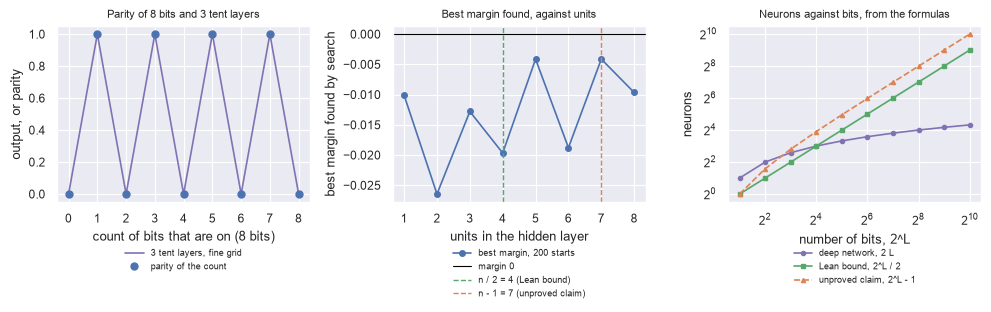

In [7]:
figure, (axis_zigzag, axis_margin, axis_neurons) = plt.subplots(1, 3, figsize=(10.0, 3.4))

fine_share = np.linspace(0.0, 1.0, 801)
tent_output = apply_tent_layers(fine_share, 3)
axis_zigzag.plot(fine_share * BIT_COUNT, tent_output, color=MODEL, linewidth=1.2, label="3 tent layers, fine grid")
axis_zigzag.plot(COUNTS, COUNTS % 2, linestyle="none", marker="o", markersize=5, color=NEAREST, label="parity of the count")
axis_zigzag.set_xlabel("count of bits that are on (8 bits)")
axis_zigzag.set_ylabel("output, or parity")
axis_zigzag.set_xticks(range(BIT_COUNT + 1))
axis_zigzag.set_title("Parity of 8 bits and 3 tent layers", fontsize=8)
axis_zigzag.legend(fontsize=6.5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.22))

best_margins = [float(search_results[unit_count]["margins"].max()) for unit_count in UNIT_COUNTS]
axis_margin.plot(UNIT_COUNTS, best_margins, marker="o", markersize=4, color=NEAREST, linewidth=1.2, label="best margin, 200 starts")
axis_margin.axhline(0.0, color="black", linewidth=0.8, label="margin 0")
axis_margin.axvline(BIT_COUNT // 2, color=BOUND, linestyle="--", linewidth=1.0, label="n / 2 = 4 (Lean bound)")
axis_margin.axvline(BIT_COUNT - 1, color=VERTICAL, linestyle="--", linewidth=1.0, label="n - 1 = 7 (unproved claim)")
axis_margin.set_xlabel("units in the hidden layer")
axis_margin.set_ylabel("best margin found by search")
axis_margin.set_xticks(UNIT_COUNTS)
axis_margin.set_title("Best margin found, against units", fontsize=8)
axis_margin.legend(fontsize=6.5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.22))

bit_totals = 2 ** FORMULA_LAYERS
axis_neurons.plot(bit_totals, 2 * FORMULA_LAYERS, marker="o", markersize=3, color=MODEL, label="deep network, 2 L")
axis_neurons.plot(bit_totals, bit_totals // 2, marker="s", markersize=3, color=BOUND, label="Lean bound, 2^L / 2")
axis_neurons.plot(bit_totals, bit_totals - 1, marker="^", markersize=3, color=VERTICAL, linestyle="--", label="unproved claim, 2^L - 1")
axis_neurons.set_xscale("log", base=2)
axis_neurons.set_yscale("log", base=2)
axis_neurons.set_xlabel("number of bits, 2^L")
axis_neurons.set_ylabel("neurons")
axis_neurons.set_title("Neurons against bits, from the formulas", fontsize=8)
axis_neurons.legend(fontsize=6.5, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.22))

figure.tight_layout()
FIGURE_PATH.parent.mkdir(parents=True, exist_ok=True)
figure.savefig(FIGURE_PATH, dpi=160, bbox_inches="tight")
print(f"wrote {FIGURE_PATH.relative_to(ROOT).as_posix()}")

## Summary of the predictions

Each line below is built from the verdicts computed above. The search found nothing or something only for the
starts and settings fixed in the first cell; a search that finds nothing does not prove that nothing exists.

In [8]:
WEAK_WHEN_Z3_FAILS = ("Z2",)           # Z2 shows nothing when the search cannot find the network that Z3 says exists
passed_but_not_evidence = [name for name in WEAK_WHEN_Z3_FAILS if VERDICTS[name] and not VERDICTS["Z3"]]
for name, passed in VERDICTS.items():
    if name in passed_but_not_evidence:
        print("[PASS, but not evidence: Z3 failed, so the search could not have found a network even if one existed] " + name)
    else:
        print(("[PASS] " if passed else "[FAIL] ") + name)
print(f"predictions passed: {sum(VERDICTS.values())} of {len(VERDICTS)}")
print(f"of those, passed but not evidence: {len(passed_but_not_evidence)} ({', '.join(passed_but_not_evidence) or 'none'}); "
      f"passed and counting as evidence: {sum(VERDICTS.values()) - len(passed_but_not_evidence)}")

[PASS] Z1
[PASS, but not evidence: Z3 failed, so the search could not have found a network even if one existed] Z2
[FAIL] Z3
[PASS] Z4
predictions passed: 3 of 4
of those, passed but not evidence: 1 (Z2); passed and counting as evidence: 2


## Diagnostic (added after the run and after a second reader's review; not one of the predictions)

Z3 failed: the search did not find a network for 7 or 8 units, although one exists. These measurements do **not change any
verdict above**; they are there to tell a weak search from a bug, and nothing in the search of Z1 to Z3 is changed.

(a) For each `k`, how many units are **dead** (the unit's ReLU is zero at all nine counts, so it gets no gradient and is
useless) at the start and at the end of training, averaged over the 200 starts.

(b) The same training (the same Adam, step size, 3,000 steps, hinge margin 0.05) started once from the known 7-unit network
of the cell for Z3. That network has margin 1 with gains up to 50. The output has no constant, so scaling the gains does not
scale the margin; instead, with the same kinks and orientations, a linear programme finds the gains of smallest largest
size whose margin is at least 0.05, which is a network of the same form whose margin is as close to 0.05 as the form allows.
Normal noise of standard deviation 0.01 (seeded) is added to every gain, slope and bias. The margin at the start, the best
margin along the way and the margin at the last step are reported.

(c) For the 200-start search, the best margin seen at **any** step (the start included), next to the last-step margin that the
stop rule uses. The same starts are redrawn from `default_rng(SEED)` in the same order, the same Adam is run, and the last-step
margins must equal the ones recorded by the search (asserted).

(d) Why the best margins for 5 and 7 units agree to six digits (-0.004136).

In [9]:
def train_networks_tracked(gains, slopes, biases):
    # The same Adam as train_networks, step for step, that also keeps the best margin seen at any step (the start included).
    parameters = [gains.copy(), slopes.copy(), biases.copy()]
    first_moment = [np.zeros_like(item) for item in parameters]
    second_moment = [np.zeros_like(item) for item in parameters]
    best_margin = compute_margins(*parameters)
    for step in range(1, STEP_COUNT + 1):
        gradients = compute_gradient(*parameters)
        for index in range(3):
            first_moment[index] = FIRST_DECAY * first_moment[index] + (1 - FIRST_DECAY) * gradients[index]
            second_moment[index] = SECOND_DECAY * second_moment[index] + (1 - SECOND_DECAY) * gradients[index] ** 2
            corrected_first = first_moment[index] / (1 - FIRST_DECAY ** step)
            corrected_second = second_moment[index] / (1 - SECOND_DECAY ** step)
            parameters[index] -= LEARNING_RATE * corrected_first / (np.sqrt(corrected_second) + EPSILON)
        best_margin = np.maximum(best_margin, compute_margins(*parameters))
    return parameters, best_margin


def count_dead_units(gains, slopes, biases):
    # A unit is dead if its ReLU is zero at all nine counts. The gain does not matter.
    pre_activation = slopes[:, :, None] * COUNTS[None, None, :] + biases[:, :, None]
    return np.sum(np.max(pre_activation, axis=2) <= 0.0, axis=1)


diagnostic_rng = np.random.default_rng(SEED)
diagnostic_rows = {}
largest_reproduction_difference = 0.0
print("(a) and (c): the 200 starts redrawn, the same training run again with the best margin at any step recorded")
print(f"{'k':>2} {'dead at start':>14} {'dead at end':>12} {'best last-step margin':>22} {'best margin at any step':>24} "
      f"{'starts > 0 at last step':>24} {'starts > 0 at some step':>24}")
for unit_count in UNIT_COUNTS:
    start_slopes = diagnostic_rng.choice([-1.0, 1.0], (START_COUNT, unit_count))
    start_kinks = diagnostic_rng.uniform(KINK_LOW, KINK_HIGH, (START_COUNT, unit_count))
    start_biases = -start_kinks * start_slopes
    start_gains = diagnostic_rng.normal(0.0, GAIN_SPREAD, (START_COUNT, unit_count))
    final_parameters, best_any_step = train_networks_tracked(start_gains, start_slopes, start_biases)
    last_margins = compute_margins(*final_parameters)
    largest_reproduction_difference = max(largest_reproduction_difference,
                                          float(np.abs(last_margins - search_results[unit_count]["margins"]).max()))
    diagnostic_rows[unit_count] = {"best_any_step": best_any_step, "last_margins": last_margins}
    print(f"{unit_count:>2} {count_dead_units(start_gains, start_slopes, start_biases).mean():>14.2f} "
          f"{count_dead_units(*final_parameters).mean():>12.2f} {float(last_margins.max()):>22.6f} "
          f"{float(best_any_step.max()):>24.6f} {int(np.sum(last_margins > 0.0)):>24d} {int(np.sum(best_any_step > 0.0)):>24d}")
check(largest_reproduction_difference < 1e-12,
      f"the redrawn starts and the tracked training reproduce the last-step margins of the search (largest difference {largest_reproduction_difference:.1e})")
print("these numbers do not change any verdict above")

print()
print("(b) the same training from the known 7-unit network")
start_orientation = best_orientation
start_basis = np.maximum(start_orientation[None, :] * (COUNTS[:, None] - KINK_POSITIONS[None, :]), 0.0)
unit_total = len(KINK_POSITIONS)
# variables: seven gains, then t. Minimise t subject to  sign * (basis @ gains - 1/2) >= HINGE_MARGIN  and  |gain| <= t.
rescale_solution = linprog(np.eye(unit_total + 1)[-1],
                           A_ub=np.vstack([np.hstack([-SIGNS[:, None] * start_basis, np.zeros((COUNTS.size, 1))]),
                                           np.hstack([np.eye(unit_total), -np.ones((unit_total, 1))]),
                                           np.hstack([-np.eye(unit_total), -np.ones((unit_total, 1))])]),
                           b_ub=np.concatenate([-0.5 * SIGNS - HINGE_MARGIN, np.zeros(2 * unit_total)]),
                           bounds=[(None, None)] * unit_total + [(0.0, None)], method="highs")
print(f"linear programme for the rescaled network: status {rescale_solution.status} (0 means a solution was found)")
rescaled_gains = rescale_solution.x[:unit_total]
rescaled_slopes = start_orientation
rescaled_biases = -start_orientation * KINK_POSITIONS
rescaled_margin = compute_margin_by_loop(rescaled_gains, rescaled_slopes, rescaled_biases)
print(f"rescaled network, margin {rescaled_margin:.6f} (aimed at {HINGE_MARGIN}), largest gain {np.abs(rescaled_gains).max():.4f} "
      f"(the first network had margin {verified_margin:.4f} and largest gain {np.abs(best_gains).max():.4f})")
noise_rng = np.random.default_rng(SEED + 1)
noisy_gains = rescaled_gains[None, :] + 0.01 * noise_rng.standard_normal((1, unit_total))
noisy_slopes = rescaled_slopes[None, :] + 0.01 * noise_rng.standard_normal((1, unit_total))
noisy_biases = rescaled_biases[None, :] + 0.01 * noise_rng.standard_normal((1, unit_total))
noisy_start_margin = float(compute_margins(noisy_gains, noisy_slopes, noisy_biases)[0])
noisy_final, noisy_best_any_step = train_networks_tracked(noisy_gains, noisy_slopes, noisy_biases)
noisy_last_margin = float(compute_margins(*noisy_final)[0])
recomputed_last_margin = compute_margin_by_loop(noisy_final[0][0], noisy_final[1][0], noisy_final[2][0])
check(abs(recomputed_last_margin - noisy_last_margin) < 1e-9,
      f"the last-step margin of the run from the known network, recomputed separately ({recomputed_last_margin:.6f} against {noisy_last_margin:.6f})")
print(f"run from the known 7-unit network with noise 0.01 on every weight: margin at the start {noisy_start_margin:.6f}, "
      f"best margin at any step {float(noisy_best_any_step[0]):.6f}, margin at the last step {noisy_last_margin:.6f}; "
      f"the last-step margin is {'above' if noisy_last_margin > 0.0 else 'not above'} 0, "
      f"dead units at the start {int(count_dead_units(noisy_gains, noisy_slopes, noisy_biases)[0])} and at the end {int(count_dead_units(*noisy_final)[0])}")

print()
print("(d) the best networks for k = 5 and k = 7")
summary_outputs, summary_margins, summary_live, summary_binding, summary_starts = {}, {}, {}, {}, {}
for unit_count in (5, 7):
    result = search_results[unit_count]
    best = result["best_index"]
    outputs = compute_outputs(result["gains"][best:best + 1], result["slopes"][best:best + 1], result["biases"][best:best + 1])[0]
    summary_outputs[unit_count] = outputs
    summary_margins[unit_count] = float(result["margins"][best])
    summary_live[unit_count] = unit_count - int(count_dead_units(result["gains"][best:best + 1], result["slopes"][best:best + 1],
                                                                result["biases"][best:best + 1])[0])
    summary_binding[unit_count] = int(np.argmin(SIGNS * (outputs - 0.5)))
    summary_starts[unit_count] = best
    print(f"  k = {unit_count} (start {best}): output at counts 0 to 8: " + ", ".join(f"{value:.6f}" for value in outputs))
output_difference = float(np.abs(summary_outputs[5] - summary_outputs[7]).max())
print(f"k = 5 and k = 7 best margins to ten digits: {summary_margins[5]:.10f} and {summary_margins[7]:.10f} "
      f"(differ by {abs(summary_margins[5] - summary_margins[7]):.1e}); start {summary_starts[5]} and start {summary_starts[7]}; "
      f"live units {summary_live[5]} and {summary_live[7]}; the count that sets the margin {summary_binding[5]} and {summary_binding[7]}; "
      f"largest difference between the two outputs over the nine counts {output_difference:.3f}, so the two networks are "
      f"{'the same function' if output_difference < 1e-6 else 'different functions'}")

(a) and (c): the 200 starts redrawn, the same training run again with the best margin at any step recorded
 k  dead at start  dead at end  best last-step margin  best margin at any step  starts > 0 at last step  starts > 0 at some step


 1           0.12         0.23              -0.010121                -0.000066                        0                        0


 2           0.18         0.43              -0.026449                -0.000068                        0                        0


 3           0.33         0.64              -0.012795                -0.000132                        0                        0


 4           0.36         0.82              -0.019669                -0.000171                        0                        0


 5           0.51         1.03              -0.004136                -0.000025                        0                        0


 6           0.67         1.19              -0.018790                -0.000290                        0                        0


 7           0.69         1.26              -0.004136                -0.000084                        0                        0


 8           0.71         1.16              -0.009655                -0.000151                        0                        0
[PASS] check: the redrawn starts and the tracked training reproduce the last-step margins of the search (largest difference 0.0e+00)
these numbers do not change any verdict above

(b) the same training from the known 7-unit network
linear programme for the rescaled network: status 0 (0 means a solution was found)
rescaled network, margin 0.050000 (aimed at 0.05), largest gain 1.0500 (the first network had margin 1.0000 and largest gain 50.0000)
[PASS] check: the last-step margin of the run from the known network, recomputed separately (0.051090 against 0.051090)
run from the known 7-unit network with noise 0.01 on every weight: margin at the start -0.027735, best margin at any step 0.072912, margin at the last step 0.051090; the last-step margin is above 0, dead units at the start 0 and at the end 0

(d) the best networks for k = 5 and k = 7
  k = 5 (start 13